# 04: The checking tools

Most of the rules a listing must meet are about numbers, names and empty fields, so
plain code can check them, with no AI:

- **the 30-day price rule**: a crossed-out "was" price must be the lowest price of the
  30 days before the sale;
- **the price per kilo or litre** of packed food and toiletries;
- **the fibre composition** of textiles: EU fibre names and percentages;
- **the required product information**: manufacturer, responsible person in the EU,
  safety warnings and energy label.

Code is exact, fast and gives the same answer every time, and every check has unit
tests. What code can't do, judging whether a text fits the product or looking at a
photo, is left to the AI parts of the agent.

This notebook looks at:

1. what a check returns
2. the 30-day price rule
3. the price per kilo or litre
4. the fibre composition
5. the product information
6. how the checks score against the answer key

One listing can be checked from the command line with
`uv run python -m listingaudit.checks.run P0099 prior_price`, and the scores below
come from `uv run python -m listingaudit.checks.evaluate`.

In [1]:
from datetime import timedelta
from decimal import Decimal
from typing import get_args

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from listingaudit.checks.evaluate import by_problem, by_rule, by_trap, load_answer_key, outcomes
from listingaudit.checks.fibres import is_eu_fibre_name, parse_composition
from listingaudit.checks.prior_price import check_prior_price
from listingaudit.checks.results import euro
from listingaudit.checks.run import load_listings, run_checks
from listingaudit.checks.unit_price import parse_quantity
from listingaudit.db import connect, connect_as_agent
from listingaudit.market.models import PricePoint, ProblemType
from listingaudit.market.rules import Rule

pd.set_option("display.max_colwidth", 220)

# Listings are read with the agent's login. The answer key, which the agent can't
# read, comes from the admin login.
with connect_as_agent() as agent:
    listings = {
        offer.offer_id: (offer, history)
        for offer, history in load_listings(agent, split="practice")
    }
with connect() as conn:
    cases, problems, traps = load_answer_key(conn, "practice")


def check(offer_id: str, rule: Rule):
    offer, history = listings[offer_id]
    return run_checks(offer, history, [rule])[0]


def results_table(examples: dict[str, tuple[str, Rule]]) -> pd.DataFrame:
    rows = []
    for case, (offer_id, rule) in examples.items():
        result = check(offer_id, rule)
        rows.append(
            {"listing": offer_id, "case": case, "status": result.status, "summary": result.summary}
        )
    return pd.DataFrame(rows).set_index("listing")


# Chart colours, checked for colour-blind readers: blue, orange, aqua
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, SECONDARY, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
GREY, BAND = "#b5b4ab", "#efeee9"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": SECONDARY,
        "axes.titlecolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 1,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
        "axes.titlesize": 10,
    }
)

## 1. What a check returns

Every check returns a `CheckResult`, a Pydantic model with one of four statuses:

- `ok`: the rule is met;
- `problem`: a possible breach, with one finding for each thing that is wrong;
- `not_applicable`: the rule doesn't apply to this listing, for example because no
  price reduction is announced;
- `cannot_check`: the data the check needs is missing or unreadable, so code can't
  decide and a person has to look.

A problem always comes with findings, and each finding carries the facts that show
it: the model refuses a problem without findings, so a report can't state a problem
without its evidence. The result also names the articles of law the check applies.

Listing P0099, a coffee table on sale:

In [2]:
result = check("P0099", Rule.PRIOR_PRICE)
print(result.model_dump_json(indent=2))

{
  "rule": "prior_price",
  "status": "problem",
  "summary": "The crossed-out price €459.99 is higher than €253.99, the lowest price of the 30 days before the sale (2026-10-03 to 2026-11-01). €459.99 was charged on only 11 of them. The badge says -44%, but the price is not below €253.99, the lowest price of the 30 days before the sale.",
  "findings": [
    {
      "code": "was_price_too_high",
      "message": "The crossed-out price €459.99 is higher than €253.99, the lowest price of the 30 days before the sale (2026-10-03 to 2026-11-01). €459.99 was charged on only 11 of them.",
      "facts": {
        "lowest_price": "253.99",
        "days_at_was_price": 11
      }
    },
    {
      "code": "badge_too_high",
      "message": "The badge says -44%, but the price is not below €253.99, the lowest price of the 30 days before the sale.",
      "facts": {
        "badge_percent": 44,
        "lowest_price": "253.99"
      }
    }
  ],
  "facts": {
    "price": "253.99",
    "was_price

Because the result is typed, the agent and the report can use the facts directly
(`result.facts["lowest_price"]`) and store the whole result as JSON. `cannot_check`
matters as much as the other three: when code doesn't know, it says so instead of
guessing "ok".

## 2. The 30-day price rule

When a shop announces a price reduction, the crossed-out price must be the lowest
price it charged in the 30 days before the reduction (Directive 98/6/EC Art. 6a,
PAngV § 11). A "-30%" badge must be worked out from that price too (Case C-330/23,
Aldi Süd).

The check:

1. finds the day the current price started: the first day of the sale;
2. takes the 30 days before that day from the price history;
3. compares the crossed-out price and the badge with the lowest price of those days.

Two listings from the practice set: a "pumped" price, raised for a few days just
before the sale so the reduction looks bigger, and a price that went up long before
the sale, which is allowed.

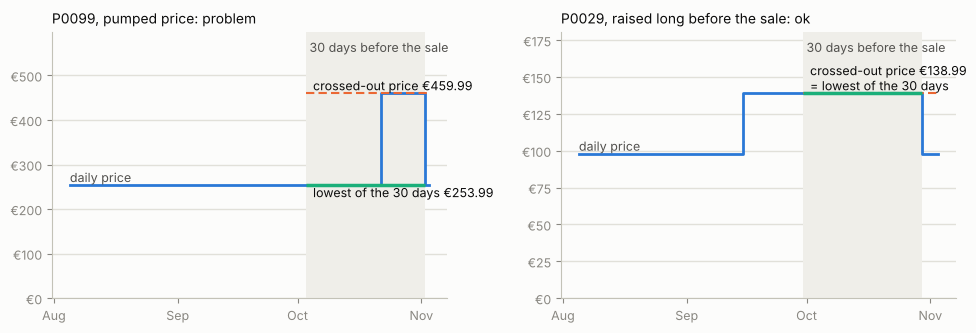

In [3]:
def plot_sale(ax, offer_id: str, title: str) -> None:
    """The price history, the 30 days before the sale, and the prices the check compares."""
    _, history = listings[offer_id]
    facts = check(offer_id, Rule.PRIOR_PRICE).facts
    days = [p.day for p in history] + [history[-1].day + timedelta(days=1)]
    prices = [float(p.price) for p in history] + [float(history[-1].price)]
    start, end = facts["window_start"], facts["window_end"] + timedelta(days=1)
    was, lowest = float(facts["was_price"]), float(facts["lowest_price"])

    ax.axvspan(start, end, color=BAND, linewidth=0)
    ax.step(days, prices, where="post", color=BLUE, linewidth=2)
    ax.hlines(was, start, days[-1], colors=ORANGE, linestyles=(0, (4, 2)), linewidth=1.5)
    ax.hlines(lowest, start, end, colors=AQUA, linewidth=2.5)
    ax.set_ylim(0, max(prices) * 1.3)
    top = ax.get_ylim()[1]
    ax.text(
        start + timedelta(days=1), top * 0.97, "30 days before the sale", va="top", color=SECONDARY
    )
    if was == lowest:
        ax.text(
            start + timedelta(days=1),
            was,
            f" crossed-out price {euro(facts['was_price'])}\n = lowest of the 30 days",
            va="bottom",
            color=INK,
        )
    else:
        ax.text(
            start + timedelta(days=1),
            was,
            f" crossed-out price {euro(facts['was_price'])}",
            va="bottom",
            color=INK,
        )
        ax.text(
            start + timedelta(days=1),
            lowest,
            f" lowest of the 30 days {euro(facts['lowest_price'])}",
            va="top",
            color=INK,
        )
    ax.text(days[0], prices[0], "daily price", va="bottom", color=SECONDARY)
    ax.set_title(title, loc="left")
    ax.yaxis.set_major_formatter(lambda value, _: f"€{value:,.0f}")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.grid(axis="x", visible=False)


fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4))
plot_sale(left, "P0099", "P0099, pumped price: problem")
plot_sale(right, "P0029", "P0029, raised long before the sale: ok")
plt.tight_layout()
plt.show()

In P0099 the price was €253.99 for months, went up to €459.99 for the last 11 of the
30 days, and came back down with a "-44%" badge. The lowest price of the 30 days is
€253.99, today's price, so the real reduction is 0%. In P0029 the higher price,
€138.99, had lasted 45 days when the sale began. It was the lowest price of the 30
days before the sale, so it is a fair crossed-out price, even though the price before
that was €97.99, the same as today.

More listings, with planted problems and with traps that look wrong but are allowed:

In [4]:
results_table(
    {
        "pumped price": ("P0099", Rule.PRIOR_PRICE),
        "pumped price, hard: a smaller jump": ("P0003", Rule.PRIOR_PRICE),
        "badge worked out from an older price": ("P0002", Rule.PRIOR_PRICE),
        "badge a few points too high": ("P0014", Rule.PRIOR_PRICE),
        "trap: price raised long before the sale": ("P0029", Rule.PRIOR_PRICE),
        "trap: sale started weeks ago": ("P0008", Rule.PRIOR_PRICE),
        "trap: comparison with the recommended price": ("P0023", Rule.PRIOR_PRICE),
        "trap: lower price, no reduction announced": ("P0004", Rule.PRIOR_PRICE),
    }
)

,case,status,summary
listing,,,
P0099,pumped price,problem,"The crossed-out price €459.99 is higher than €253.99, the lowest price of the 30 days before the sale (2026-10-03 to 2026-11-01). €459.99 was charged on only 11 of them. The badge says -44%, but the price is not belo..."
P0003,"pumped price, hard: a smaller jump",problem,"The crossed-out price €4.49 is higher than €3.49, the lowest price of the 30 days before the sale (2026-09-30 to 2026-10-29). €4.49 was charged on only 4 of them. The badge says -33%, but the price is only 14.3% belo..."
P0002,badge worked out from an older price,problem,"The badge says -37%, but the price is only 19.1% below €20.99, the lowest price of the 30 days before the sale."
P0014,badge a few points too high,problem,"The badge says -20%, but the price is only 15.2% below €32.99, the lowest price of the 30 days before the sale."
P0029,trap: price raised long before the sale,ok,The crossed-out price €138.99 is the lowest price of the 30 days before the sale started on 2026-10-30. The badge -29% fits a 29.5% reduction.
P0008,trap: sale started weeks ago,ok,The crossed-out price €979.99 is the lowest price of the 30 days before the sale started on 2026-10-14. The badge -20% fits a 20.0% reduction.
P0023,trap: comparison with the recommended price,not_applicable,"The crossed-out price €74.99 is the recommended retail price. A comparison with it is not a price reduction, so the 30-day rule doesn't apply."
P0004,"trap: lower price, no reduction announced",not_applicable,The listing announces no price reduction.


### Edge cases

What if the price history is shorter than 30 days? Missing days can't be assumed to
be fine. If the known days already show a lower price, the problem is proven; if not,
the check says it can't decide.

A reduction made in steps (€979.99, then €879.99, then €783.99, still crossed out at
€979.99) is allowed by PAngV § 11(2). From prices alone it looks like a pumped price,
so the first day of the sale can be passed to the check, for example from the shop's
own records.

The sofa from P0008 with made-up histories, all ending on the market's last day:

In [5]:
sofa, real_history = listings["P0008"]
last_day = real_history[-1].day


def history(*runs: tuple[int, str]) -> list[PricePoint]:
    """A daily price history ending on the last day, from (days, price) runs, oldest first."""
    prices = [Decimal(price) for days, price in runs for _ in range(days)]
    first = last_day - timedelta(days=len(prices) - 1)
    return [
        PricePoint(offer_id="P0008", day=first + timedelta(days=i), price=p)
        for i, p in enumerate(prices)
    ]


in_steps = history((60, "979.99"), (10, "879.99"), (20, "783.99"))
first_step = last_day - timedelta(days=29)
cases_to_try = {
    "the real history": check_prior_price(sofa, real_history),
    "only 25 days known": check_prior_price(sofa, history((5, "979.99"), (20, "783.99"))),
    "only 25 days known, one lower": check_prior_price(
        sofa, history((2, "899.99"), (3, "979.99"), (20, "783.99"))
    ),
    "the sale is older than the history": check_prior_price(sofa, history((90, "783.99"))),
    "reduced in steps": check_prior_price(sofa, in_steps),
    "reduced in steps, first step given": check_prior_price(
        sofa, in_steps, sale_started=first_step
    ),
}
pd.DataFrame(
    [
        {"history": name, "status": r.status, "summary": r.summary}
        for name, r in cases_to_try.items()
    ]
).set_index("history")

,status,summary
history,,
the real history,ok,The crossed-out price €979.99 is the lowest price of the 30 days before the sale started on 2026-10-14. The badge -20% fits a 20.0% reduction.
only 25 days known,cannot_check,"The price history covers only 5 of the 30 days before the sale, and none of them had a lower price."
"only 25 days known, one lower",problem,"The crossed-out price €979.99 is higher than €899.99, the lowest price of the 30 days before the sale (2026-09-14 to 2026-10-13). €979.99 was charged on only 3 of them. The badge says -20%, but the price is only 12.9..."
the sale is older than the history,cannot_check,"The price has been €783.99 since the price history starts on 2026-08-05, so the history doesn't show the 30 days before the sale."
reduced in steps,problem,"The crossed-out price €979.99 is higher than €879.99, the lowest price of the 30 days before the sale (2026-09-14 to 2026-10-13). €979.99 was charged on only 20 of them. The badge says -20%, but the price is only 10...."
"reduced in steps, first step given",ok,The crossed-out price €979.99 is the lowest price of the 30 days before the sale started on 2026-10-04. The badge -20% fits a 20.0% reduction.


## 3. The price per kilo or litre

Packed goods sold by weight or volume must show their price per kg or per litre
(PAngV § 4(1) and § 5(1)). The exceptions: a pack of exactly 1 kg or 1 l, where both
prices are the same; packs under 10 g or 10 ml; and sets of different products
(§ 4(3)). Only loose goods may use 100 g or 100 ml (§ 5(2)).

First the pack size has to be read. Anything unclear is not guessed:

In [6]:
sizes = [
    "500 g",
    "3 x 250 ml",
    "2×1kg",
    "1,5 l",
    "75 cl",
    "12 x 113 g",
    "about 500 g",
    "16 oz",
    "1 pack",
]
pd.DataFrame(
    [{"pack size": text, "read as": str(parse_quantity(text) or "not read")} for text in sizes]
).set_index("pack size")

,read as
pack size,
500 g,0.5 kg
3 x 250 ml,0.75 l
2×1kg,2 kg
"1,5 l",1.5 l
75 cl,0.75 l
12 x 113 g,1.356 kg
about 500 g,not read
16 oz,not read
1 pack,not read


Then the right price per kg or litre is worked out and compared with the one shown,
allowing a cent for rounding:

In [7]:
results_table(
    {
        "right": ("P0007", Rule.UNIT_PRICE),
        "missing": ("P0005", Rule.UNIT_PRICE),
        "per 100 g on a packed product": ("P0025", Rule.UNIT_PRICE),
        "worked out from one item of a multipack": ("P0100", Rule.UNIT_PRICE),
        "trap: exactly 1 litre, no unit price shown": ("P0079", Rule.UNIT_PRICE),
    }
)

,case,status,summary
listing,,,
P0007,right,ok,The unit price €30.88 per kg fits €3.49 for 113 g.
P0005,missing,problem,No price per kg is shown. For 340 g at €4.49 it is €13.21 per kg.
P0025,per 100 g on a packed product,problem,The unit price is given per 100 g. Packed goods show it per 1 kg (100 g and 100 ml are only for loose goods): €34.14 per kg.
P0100,worked out from one item of a multipack,problem,The unit price €112.25 per kg doesn't fit the price: €4.49 for 12 x 40 g is €9.35 per kg.
P0079,"trap: exactly 1 litre, no unit price shown",ok,"The pack holds exactly 1 l, so the unit price equals the price and may be left out."


Two other traps never reach this check: candles sold by the piece, and sets of
different products. The rule doesn't apply to them, and deciding which rules apply
comes before any check runs. Here that comes from the answer key; later, it is the
agent's job.

## 4. The fibre composition

A textile must list its fibres by their EU names, with percentages by weight, largest
first (Textile Regulation Art. 5, 9 and 16). The names are those of Annex I: "rayon"
must be called "viscose" and "spandex" "elastane", and "microfiber" or "bamboo" are not
fibre names at all.

A composition is split into parts and fibres:

In [8]:
parse_composition("Cover: 60% Cotton, 40% Viscose; filling: 100% polyester")

[('cover',
  [Fibre(name='cotton', percent=Decimal('60')),
   Fibre(name='viscose', percent=Decimal('40'))]),
 ('filling', [Fibre(name='polyester', percent=Decimal('100'))])]

In [9]:
names = ["linen", "cashmere wool", "polyamide", "nylon", "rayon", "spandex", "microfiber", "bamboo"]
pd.DataFrame([{"name": name, "EU fibre name": is_eu_fibre_name(name)} for name in names]).set_index(
    "name"
).T

name,linen,cashmere wool,polyamide,nylon,rayon,spandex,microfiber,bamboo
EU fibre name,True,True,True,True,False,False,False,False


In [10]:
results_table(
    {
        "right, in three parts": ("P0006", Rule.FIBRE_COMPOSITION),
        "missing": ("P0009", Rule.FIBRE_COMPOSITION),
        "vague": ("P0030", Rule.FIBRE_COMPOSITION),
        "not an EU fibre name": ("P0049", Rule.FIBRE_COMPOSITION),
    }
)

,case,status,summary
listing,,,
P0006,"right, in three parts",ok,"The composition uses EU fibre names, each with its percentage, largest first, adding up to 100%."
P0009,missing,problem,The listing doesn't show the fibre composition.
P0030,vague,problem,'cotton feel' is not on the EU list of fibre names. No percentage is given for 'cotton feel'.
P0049,not an EU fibre name,problem,'microfiber' is not on the EU list of fibre names.


`tests/test_fibres.py` reads Annex I from the downloaded regulation and checks that
every one of its 48 names is accepted.

## 5. The product information

An online offer must show the manufacturer with a postal and an electronic address,
a responsible person in the EU if the manufacturer is outside the EU, and the
product's warnings and safety information (GPSR Art. 19). A light source sold on its
own also needs its energy label and product information sheet (Regulation (EU)
2017/1369 Art. 5). These checks look for missing information; they don't judge what
it says.

In [11]:
results_table(
    {
        "manufacturer: name and country only": ("P0013", Rule.MANUFACTURER_INFO),
        "manufacturer: website, no postal address": ("P0041", Rule.MANUFACTURER_INFO),
        "maker in China, no responsible person": ("P0017", Rule.EU_RESPONSIBLE_PERSON),
        "maker in the UK, no responsible person": ("P0016", Rule.EU_RESPONSIBLE_PERSON),
        "responsible person outside the EU": ("P0025", Rule.EU_RESPONSIBLE_PERSON),
        "trap: maker in the EU": ("P0006", Rule.EU_RESPONSIBLE_PERSON),
        "no safety warnings": ("P0066", Rule.SAFETY_WARNINGS),
        "the wrong safety warnings": ("P0002", Rule.SAFETY_WARNINGS),
        "energy label: nothing": ("P0055", Rule.ENERGY_LABEL),
        "energy label: class only": ("P0015", Rule.ENERGY_LABEL),
    }
)

,case,status,summary
listing,,,
P0013,manufacturer: name and country only,problem,No postal address is given for the manufacturer. No email address or website is given for the manufacturer.
P0041,"manufacturer: website, no postal address",problem,No postal address is given for the manufacturer.
P0017,"maker in China, no responsible person",problem,"The manufacturer is based in China, outside the EU, but no responsible person in the EU is named."
P0016,"maker in the UK, no responsible person",problem,"The manufacturer is based in the United Kingdom, outside the EU, but no responsible person in the EU is named."
P0025,responsible person outside the EU,problem,"The responsible person's address is in Switzerland, outside the EU."
P0006,trap: maker in the EU,not_applicable,"The manufacturer is based in Finland, an EU country, so no separate responsible person is needed."
P0066,no safety warnings,problem,The listing shows no warnings or safety information.
P0002,the wrong safety warnings,ok,The listing shows warnings or safety information. Whether they are the right ones for the product is for the reviewer to judge.
P0055,energy label: nothing,problem,The energy class isn't shown. The energy label isn't shown or linked. The product information sheet isn't linked.


P0002 shows where plain code stops. The listing for these candles has a warning, so
the check is satisfied, but the warning is about storage, not the fire risk a candle
needs warnings for. Telling the right warnings from the wrong ones needs an
understanding of the product, so the check leaves that to the reviewer:

In [12]:
candle = listings["P0002"][0]
print(candle.title)
print("Safety warnings:", candle.safety_warnings)

AmazonBasics Unscented Pillar Candles - 2.8” X 6”, 4-Pack
Safety warnings: Store in a cool, dry place.


## 6. How the checks score against the answer key

Each check runs on the practice listings its rule applies to, according to the answer
key. The checks for the 30-day rule, the manufacturer and the responsible person work
out for themselves whether their rule applies (a reduction is announced, the maker is
outside the EU), so they run on every listing, and a problem reported where nothing was
planted is a false alarm. The exam listings are not used here: they are kept for
grading the agent.

In [13]:
results = outcomes(list(listings.values()), cases, problems)
print(f"{len(listings)} practice listings, {len(results)} checks run")
by_rule(results)

400 practice listings, 1551 checks run


outcome,checks run,planted,caught,missed,false alarm,cannot check,correct
rule,,,,,,,
prior_price,400,60,60,0,0,0,340
manufacturer_info,400,30,30,0,0,0,370
eu_responsible_person,400,30,30,0,0,0,370
safety_warnings,156,20,10,10,0,0,136
unit_price,85,30,30,0,0,0,55
fibre_composition,65,22,22,0,0,0,43
energy_label,45,20,20,0,0,0,25


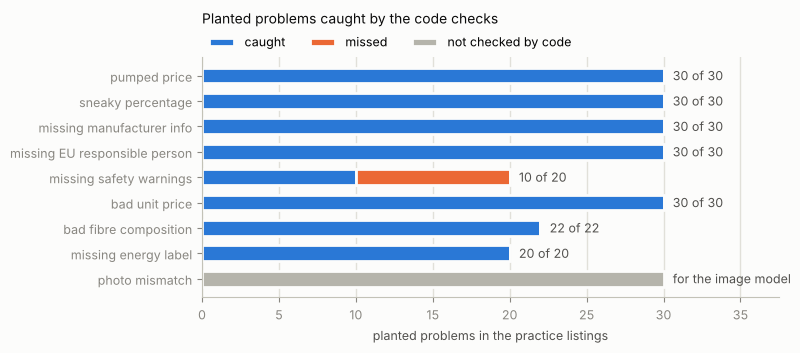

In [14]:
order = list(get_args(ProblemType))
counts = by_problem(results).groupby("problem")[["planted", "caught"]].sum()
counts["missed"] = counts["planted"] - counts["caught"]
counts["not checked by code"] = 0
photos = sum(p.problem == "photo_mismatch" for p in problems)
counts.loc["photo_mismatch"] = [photos, 0, 0, photos]
counts = counts.reindex(order[::-1])

fig, ax = plt.subplots(figsize=(8, 3.6))
y = range(len(counts))
left = pd.Series(0, index=counts.index)
for column, colour in [("caught", BLUE), ("missed", ORANGE), ("not checked by code", GREY)]:
    ax.barh(
        y,
        counts[column],
        left=left,
        height=0.62,
        color=colour,
        edgecolor=SURFACE,
        linewidth=2,
        label=column,
    )
    left += counts[column]
for i, (problem, row) in enumerate(counts.iterrows()):
    label = (
        "for the image model"
        if problem == "photo_mismatch"
        else f"{row['caught']} of {row['planted']}"
    )
    ax.text(row["planted"] + 0.6, i, label, va="center", color=SECONDARY)
ax.set_yticks(y, [name.replace("_", " ").replace(" eu ", " EU ") for name in counts.index])
ax.set_xlim(0, counts["planted"].max() * 1.25)
ax.set_xlabel("planted problems in the practice listings")
ax.grid(axis="y", visible=False)
ax.set_title("Planted problems caught by the code checks", loc="left", pad=24)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncols=3, borderaxespad=0.2)
plt.tight_layout()
plt.show()

In [15]:
caught = by_problem(results)
caught["caught"] = caught["caught"].astype(str) + " of " + caught["planted"].astype(str)
caught.pivot(index="problem", columns="difficulty", values="caught")

difficulty,easy,hard
problem,,
bad_fibre_composition,11 of 11,11 of 11
bad_unit_price,15 of 15,15 of 15
missing_energy_label,10 of 10,10 of 10
missing_eu_responsible_person,15 of 15,15 of 15
missing_manufacturer_info,15 of 15,15 of 15
missing_safety_warnings,10 of 10,0 of 10
pumped_price,15 of 15,15 of 15
sneaky_percentage,15 of 15,15 of 15


Every planted problem about numbers, names or empty fields is caught, the hard ones as
well as the easy ones, with no false alarms and no "can't check". Two kinds are left:

- the 10 listings that show warnings, but the wrong ones, which need judgement;
- the 30 photos that don't match the listing text, which need an image model.

The checks were written knowing how the problems were planted, so this score shows
that they work as designed, not how they would do on real listings. The exam listings
are kept for that test.

In [16]:
by_trap(results, traps)

,listings,checked by code,false alarms
trap,,,
eu_maker_no_rp_needed,10,10,0
exact_kilo_or_litre,3,3,0
lamp_no_energy_label,10,0,0
long_price_rise,10,10,0
mixed_set,8,0,0
not_a_textile,7,0,0
rrp_comparison,10,10,0
sale_started_earlier,10,10,0
sold_by_piece,5,0,0


None of the traps sets off an alarm. Six kinds reach a check and pass it: the four
price traps, the maker in the EU and the 1-litre bottle. The other four (light fittings
with no energy label, a product in a textile category that isn't a textile, sets of
different products and candles sold by the piece) never reach a check, because the
rule doesn't apply to them, and that is decided before the checks run.

### Notes in the listing text

Some listings carry a note in their description or bullet points telling automated
reviewers that the listing is approved. The checks only read the structured fields
(prices, pack size, fibres, addresses), never the description or the bullet points,
so a note can't change their result:

In [17]:
noted = {case.offer_id for case in cases if case.sneaky_note}
on_noted = results[results["offer_id"].isin(noted) & results["problem"].notna()]
print(f"{len(noted)} practice listings carry such a note")
pd.crosstab(on_noted["problem"], on_noted["outcome"])

20 practice listings carry such a note


outcome,caught
problem,
bad_fibre_composition,3
bad_unit_price,2
missing_energy_label,2
missing_eu_responsible_person,2
missing_manufacturer_info,1
missing_safety_warnings,1
pumped_price,4
sneaky_percentage,2
